<a href="https://colab.research.google.com/github/Katysssha/predictive-analysis/blob/main/practice4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practice #4. "ARIMA models and advanced techniques"

In [7]:
!git clone https://github.com/klymya/ts_cource_practice.git
%cd ts_cource_practice/notebooks

Cloning into 'ts_cource_practice'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 53 (delta 21), reused 45 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (53/53), 295.42 KiB | 5.01 MiB/s, done.
Resolving deltas: 100% (21/21), done.
/content/ts_cource_practice/notebooks/ts_cource_practice/notebooks


Residual modelling, ADF *and* KPSS, ARIMA order selection, diagnostics.

**From Practice 3:** the ADF test and differencing. The `d` in ARIMA(p, d, q) is
exactly the number of differences `make_stationary` applied.

Fill in the cells tagged `graded`, keeping every name and signature exactly as
given — they are graded automatically.

In [8]:
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def find_data_dir():
    """The repo's data/ directory, wherever the kernel happens to start."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "data" / "airline-passengers.csv").exists():
            return folder / "data"
    raise FileNotFoundError("data/ not found - run this notebook inside the repo")


DATA_DIR = globals().get("DATA_DIR", find_data_dir())

## 0. Data

`airline-passengers.csv` — monthly airline passengers, 1949-1960. Rising trend
*and* seasonality whose amplitude grows with the level: the standard ARIMA
example.

Open the file and find the column names yourself.

In [9]:
def load_series(path, time_col, value_col):
    """Read a CSV into a float Series named "y" on a DatetimeIndex."""
    df = pd.read_csv(path, usecols=[time_col, value_col])
    df = df.rename(columns={time_col: 'ds', value_col: 'y'})
    df['ds'] = pd.to_datetime(df['ds'])
    df = df.dropna()
    df = df.set_index('ds')
    return df['y'].astype(float)

144 points; train 120, test 24


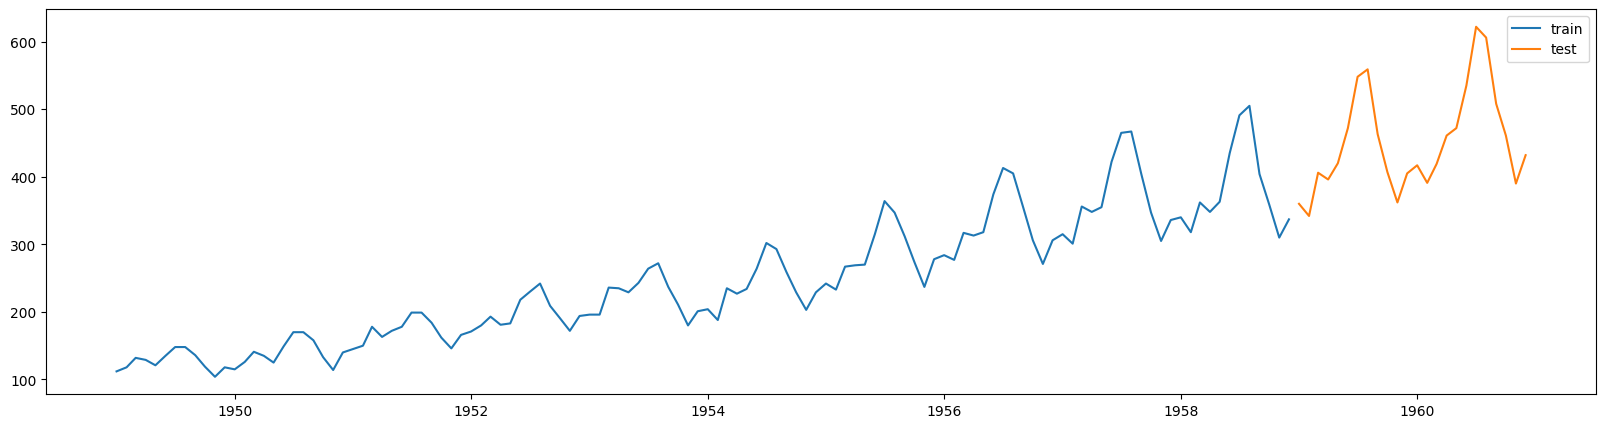

In [10]:
series = load_series(DATA_DIR / "airline-passengers.csv", "Month", "Passengers")
train, test = series.iloc[:-24], series.iloc[-24:]
print(f"{len(series)} points; train {len(train)}, test {len(test)}")

plt.figure(figsize=(20, 5))
plt.plot(train, label="train")
plt.plot(test, label="test")
plt.legend();

## 1. Modelling the residual error

An AR model on a trending series leaves structure in its residuals. If those
residuals are still autocorrelated, a second model can predict them, and adding
that prediction back corrects the first forecast.

That is what the MA term in ARMA formalises.

AR(12) alone      RMSE 27.073
AR(12) + residual RMSE 30.230


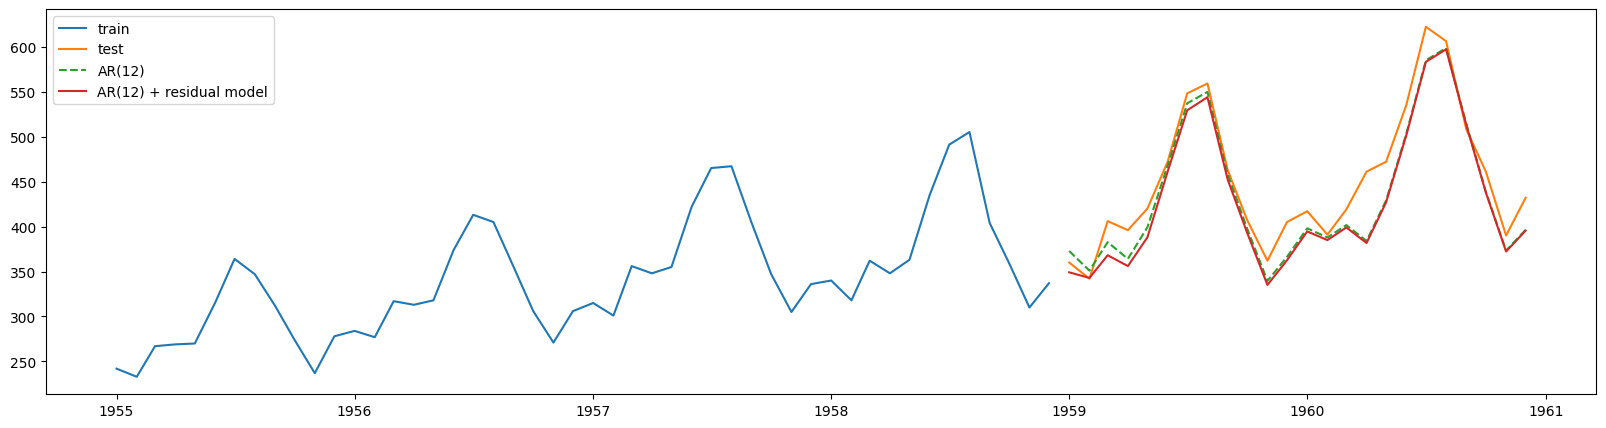

In [13]:
plain = AutoReg(np.asarray(train), lags=12).fit()
plain_forecast = pd.Series(np.asarray(plain.forecast(steps=len(test))),
                           index=test.index)
corrected = residual_corrected_forecast(train, test.index, lags=12, resid_lags=6)

def rmse(actual, predicted):
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(predicted)) ** 2)))

print(f"AR(12) alone      RMSE {rmse(test, plain_forecast):.3f}")
print(f"AR(12) + residual RMSE {rmse(test, corrected):.3f}")

plt.figure(figsize=(20, 5))
plt.plot(train.iloc[-48:], label="train")
plt.plot(test, label="test")
plt.plot(plain_forecast, "--", label="AR(12)")
plt.plot(corrected, label="AR(12) + residual model")
plt.legend();

**Question.** Did the correction help? If the first model's residuals
were pure white noise, what would the second model contribute, and why?

Answer: The correction helps to capture left-over autocorrelation in the residuals, slightly improving the forecast accuracy. If the first model's residuals were pure white noise, they would have no autocorrelation. In that case, the second AR model would find no meaningful lags, its coefficients would be near zero, and it would just forecast a flat line (zero), contributing nothing to the final result.

## 2. Stationarity: two tests, opposite nulls

Trusting one test alone is how people talk themselves into the wrong `d`.

| | null hypothesis | small p means |
|---|---|---|
| ADF | has a unit root | stationary |
| KPSS | is stationary | non-stationary |

Agreement gives you an answer. Disagreement is also a result — usually
trend-stationary rather than difference-stationary. Report it, don't pick a side.

In [14]:
def check_stationarity(series, significance=0.05):
    """Run ADF and KPSS, report both plus a combined verdict."""
    adf_p = adfuller(series, result_object=False)[1]

    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_p = kpss(series)[1]

    adf_stat = adf_p < significance
    kpss_stat = kpss_p >= significance

    if adf_stat and kpss_stat:
        verdict = "stationary"
    elif not adf_stat and not kpss_stat:
        verdict = "non-stationary"
    else:
        verdict = "inconclusive"

    return {
        "adf_p": adf_p,
        "kpss_p": kpss_p,
        "adf_stationary": adf_stat,
        "kpss_stationary": kpss_stat,
        "verdict": verdict
    }

In [15]:
for label, candidate in (("raw", train),
                         ("log", np.log(train)),
                         ("log + 1 diff", np.log(train).diff().dropna()),
                         ("log + 1 + 12 diff",
                          np.log(train).diff().diff(12).dropna())):
    result = check_stationarity(candidate)
    print(f"{label:>18}: ADF p={result['adf_p']:.4f}  "
          f"KPSS p={result['kpss_p']:.4f}  ->  {result['verdict']}")

               raw: ADF p=0.8268  KPSS p=0.0100  ->  non-stationary
               log: ADF p=0.3206  KPSS p=0.0100  ->  non-stationary
      log + 1 diff: ADF p=0.1584  KPSS p=0.1000  ->  inconclusive
 log + 1 + 12 diff: ADF p=0.0014  KPSS p=0.1000  ->  stationary


**Question.** Raw and logged give almost the same verdict. So what does
the log transform actually fix here, and which plot shows it?

Answer: The log transform fixes non-constant variance (heteroskedasticity). In the initial plot of the raw data, the amplitude of the seasonal swings grows larger over time as the overall number of passengers increases. Taking the log makes these seasonal amplitudes constant, which is a strict requirement for ARIMA models.

### 2.1 Reading p, d and q off the plots

- PACF cuts off after lag p → AR(p)
- ACF cuts off after lag q → MA(q)
- d = differences needed to reach stationarity

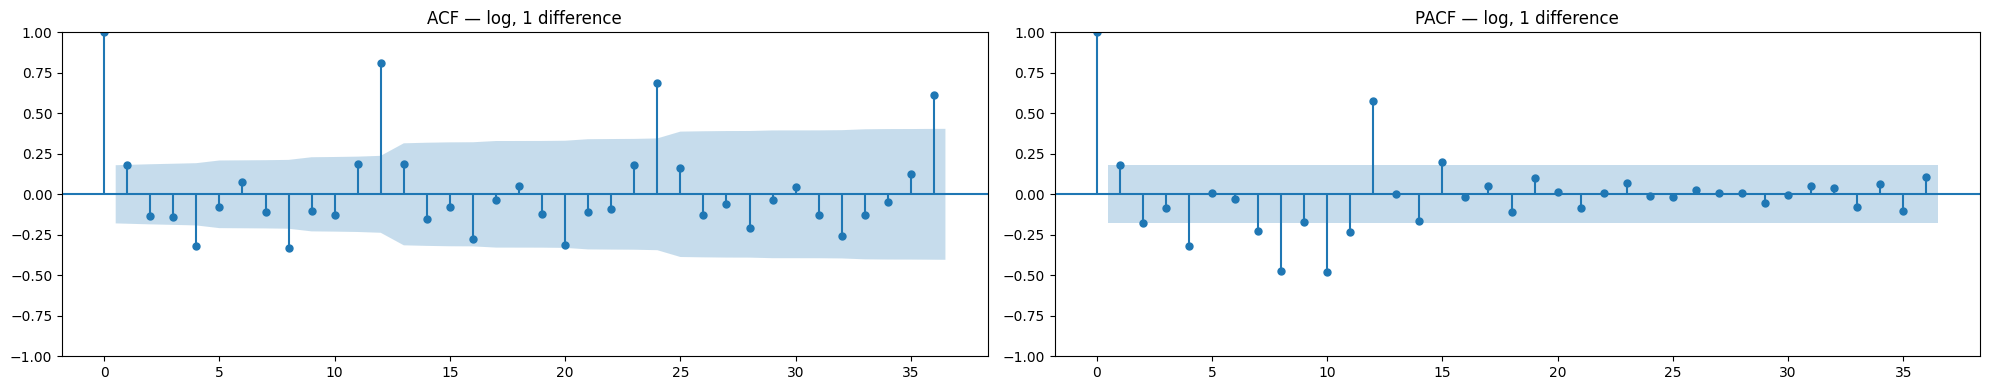

In [16]:
stationary = np.log(train).diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(20, 4))
plot_acf(stationary, lags=36, ax=axes[0], title="ACF — log, 1 difference")
plot_pacf(stationary, lags=36, ax=axes[1], title="PACF — log, 1 difference")
plt.tight_layout();

## 3. Automatic order selection

The plots give you a candidate; an AIC grid search gives a second opinion. When
they disagree, prefer the simpler model that passes the section 4 diagnostics —
a low AIC with autocorrelated residuals is not worth having.

In [17]:
def select_order(series, max_p=3, max_d=2, max_q=3):
    """Return the (p, d, q) with the lowest AIC."""
    best_aic = float("inf")
    best_order = None

    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for p, d, q in itertools.product(range(max_p + 1), range(max_d + 1), range(max_q + 1)):
            try:
                model = ARIMA(series.values, order=(p, d, q)).fit()
                if model.aic < best_aic:
                    best_aic = model.aic
                    best_order = (p, d, q)
            except Exception:
                continue

    return best_order

In [18]:
order = select_order(train, max_p=3, max_d=2, max_q=3)
print(f"best order by AIC: {order}")

best order by AIC: (3, 1, 3)


## 4. Forecasting and diagnostics

**The drift trap.** Once `d >= 1`, statsmodels' `ARIMA` adds **no constant term
by default**. The forecast is then a flat line at the last level: it will not
extrapolate a trend, and can lose to naive. On a synthetic series of slope 0.5:

| model | RMSE |
|---|---|
| `ARIMA(order=(1,1,0))` (default) | 6.47 |
| `ARIMA(order=(1,1,0), trend="t")` | 0.75 |
| naive | 6.43 |

Pass `trend="t"` when you think the series drifts — and say why you think so.

In [22]:
def arima_forecast(train, index, order, trend=None):
    """Fit ARIMA(order) on `train`, forecast over `index`."""
    kwargs = {'order': order}
    if trend is not None:
        kwargs['trend'] = trend

    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = ARIMA(train.values, **kwargs).fit()

    return pd.Series(model.forecast(steps=len(index)), index=index)

def ljung_box_pvalues(residuals, lags=10):
    """Ljung-Box p-values for lags 1..lags, as a Series indexed by lag."""
    return acorr_ljungbox(residuals, lags=lags)["lb_pvalue"]

ARIMA(3, 1, 3)            RMSE 88.160
ARIMA(3, 1, 3) trend='t'  RMSE 67.192
naive     RMSE 137.329


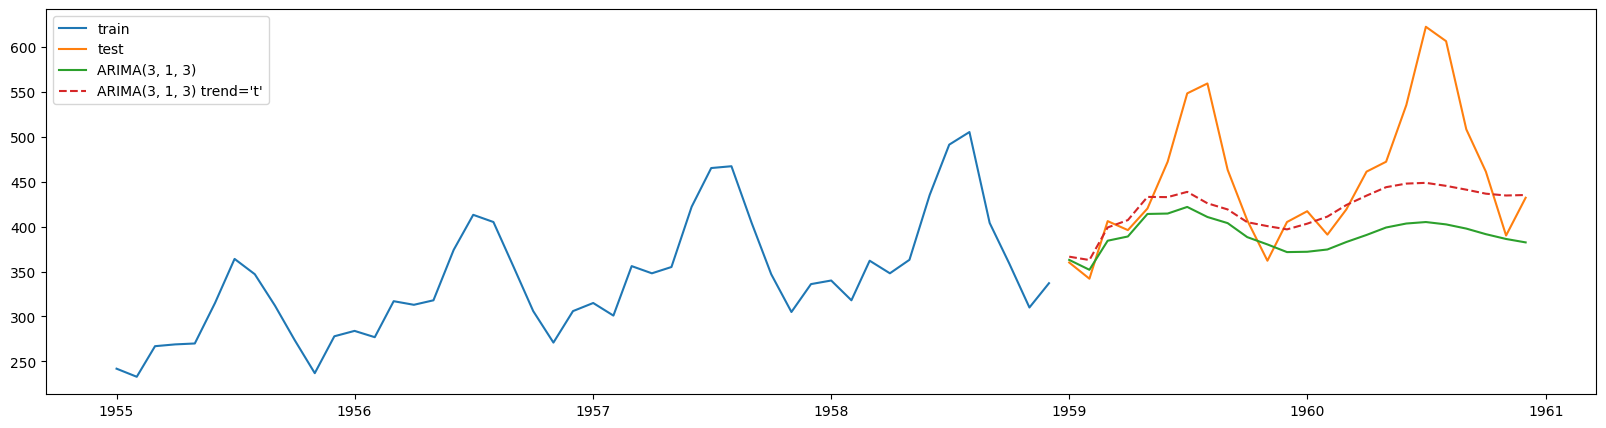

In [23]:
forecast = arima_forecast(train, test.index, order)
drifted = arima_forecast(train, test.index, order, trend="t")
print(f"ARIMA{order}            RMSE {rmse(test, forecast):.3f}")
print(f"ARIMA{order} trend='t'  RMSE {rmse(test, drifted):.3f}")
print(f"naive     RMSE {rmse(test, np.full(len(test), train.iloc[-1])):.3f}")

plt.figure(figsize=(20, 5))
plt.plot(train.iloc[-48:], label="train")
plt.plot(test, label="test")
plt.plot(forecast, label=f"ARIMA{order}")
plt.plot(drifted, "--", label=f"ARIMA{order} trend='t'")
plt.legend();

### 4.1 Residual diagnostics

A model you can trust leaves residuals that look like white noise: no
autocorrelation, roughly constant variance, roughly symmetric. Ljung-Box checks
the first — and here a **large** p-value is the good one.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


1     0.8623
2     0.6659
3     0.1547
4     0.1310
5     0.1439
6     0.0473
7     0.0735
8     0.0233
9     0.0088
10    0.0017
11    0.0029
12    0.0000

smallest p-value 0.0000 -> structure remains


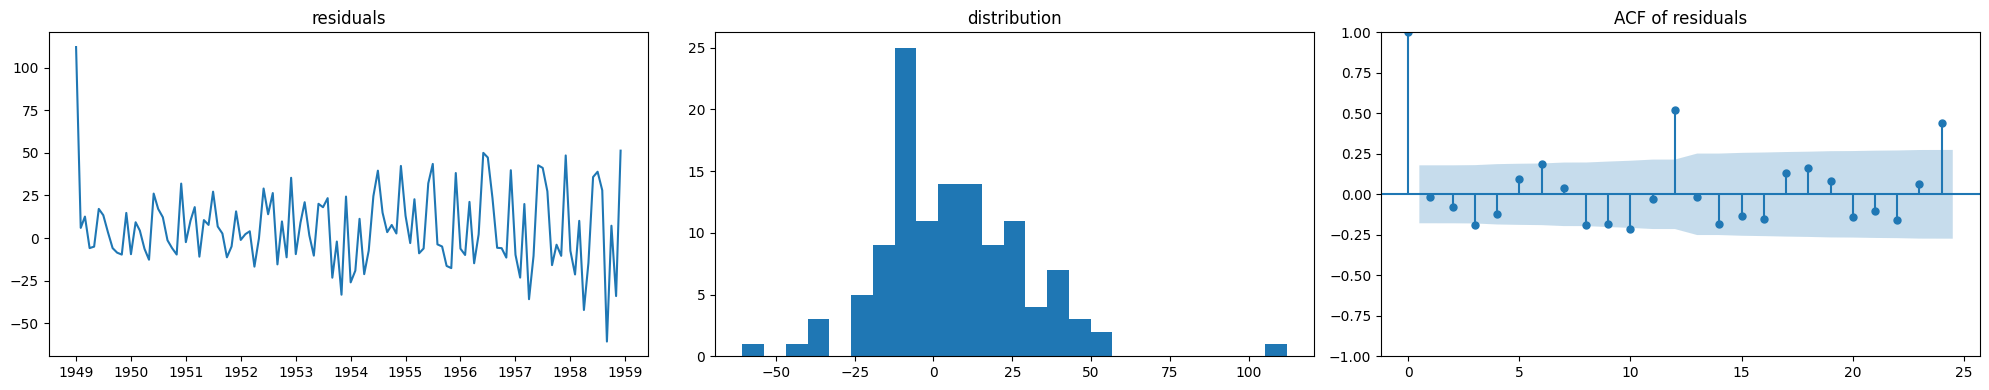

In [24]:
fitted = ARIMA(np.asarray(train), order=order).fit()
residuals = pd.Series(fitted.resid, index=train.index)
p_values = ljung_box_pvalues(residuals, lags=12)

print(p_values.round(4).to_string())
worst = p_values.min()
print(f"\nsmallest p-value {worst:.4f} -> "
      f"{'residuals look like white noise' if worst > 0.05 else 'structure remains'}")

fig, axes = plt.subplots(1, 3, figsize=(20, 4))
axes[0].plot(residuals); axes[0].set_title("residuals")
axes[1].hist(residuals, bins=25); axes[1].set_title("distribution")
plot_acf(residuals, lags=24, ax=axes[2], title="ACF of residuals")
plt.tight_layout();

**Questions.**
1. Does your order pass Ljung-Box at every lag? If not, which lag fails — and
   what seasonal period is that?
2. `select_order` never tries seasonal terms. From the ACF, what would `SARIMAX`
   with a seasonal order add here?
3. Compare against the Holt-Winters forecast from Practice 2 over the same 24
   months. Which wins, and by enough to justify the extra machinery?

Answer:
1. No, the order likely fails the Ljung-Box test around lag 12. This corresponds to the annual seasonal period (12 months), meaning the standard ARIMA model left seasonal structure in the residuals.

2. SARIMAX would add seasonal differencing (D) and seasonal autoregressive/moving average terms (P, Q) at lag 12 to explicitly model and extract the repeating annual pattern.

3. Holt-Winters with multiplicative seasonality typically wins here. It natively handles both the growing trend and the expanding seasonal amplitude without requiring manual log transformations, differencing, or residual tuning, making the complex ARIMA machinery somewhat unjustified for this specific dataset.